# Notebook 9b (lag y+1, Option B) — `9b_sectors_3dim_lagB`

## Overview

**Purpose:** Lagged robustness check on the 17 sector results: regress each sector's growth at year *t* on the three composite flood dimensions at *t−1* (flood lagged, controls contemporaneous), to test whether sector effects are immediate or delayed.

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` + `pre_transform` sheets) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

## Workflow

| Step | Description |
|---|---|
| 1 | Load the panel and define the flood predictors and controls |
| 2 | Pre-estimation tests (missing values, VIF, panel balance, predictor correlation) |
| 3 | Estimator selection — CEM vs FE vs RE (Chow, LM, Hausman/Mundlak) |
| 4 | Significance across the 17 sectors — uncorrected vs BH-FDR, per flood dimension |
| 5 | Clustered vs Driscoll–Kraay — per-sector comparison and per-sector Pesaran CD test |
| 6 | Model evaluation and robustness (residual diagnostics, control ladder, SE and sample) |
| 7 | Model fit summary per sector (within-R², AIC, BIC, RMSE) and aggregate |
| 8 | Save per-sector results and the master sector table for the dashboard |

## Outputs

| File | Description |
|---|---|
| `fit_9b.json` | Per-sector × per-dimension coefficients, lagged specification |

> **Lagged specification (y+1).** The sector outcome at year *t* is regressed on flood exposure at *t−1* with contemporaneous controls, and compared against the contemporaneous specification.

---
## STEP 1 — Load the panel and build the lagged specification

Load the Notebook 8 panel, shift the three flood dimensions one year within each regency (Option B), and define the controls. The first year per regency is dropped.

In [2]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Load the panel
# ═════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS
from numpy.linalg import inv
from scipy.stats import chi2, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

PANEL_PATH = "../data/processed/8_panel_data.xlsx"
_t = pd.read_excel(PANEL_PATH, sheet_name="transformed")
_p = pd.read_excel(PANEL_PATH, sheet_name="pre_transform")
_id = ["bps_kab_code","year"]; _rc = [c for c in _p.columns if c not in _t.columns]
panel = _t.merge(_p[_id+_rc], on=_id, how="left").sort_values(["bps_kab_code","year"])

# ════════════════════════════════════════════════════════════════════
# LAG y+1 — Option B: flood lagged, controls contemporaneous
# Rationale (supervisor): flood impacts may surface one year later,
# while population/schooling are better measured in the current year.
# Model: Outcome_t ~ Flood_{t-1} + Controls_t + entity + time effects.
# Only the flood predictors are shifted one year within each regency;
# the first year per regency is dropped (no t-1 flood available).
# ════════════════════════════════════════════════════════════════════
_FLOOD_RAW = ["event_count_log", "HCI_log", "PDI_log"]
for _c in _FLOOD_RAW:
    panel[f"{_c}_lag1"] = panel.groupby("bps_kab_code")[_c].shift(1)
FLOOD    = [f"{_c}_lag1" for _c in _FLOOD_RAW]
CONTROLS = ["log_population", "rls_years"]
X = FLOOD + CONTROLS
pdat = panel.set_index(["bps_kab_code","year"])
print(f"Loaded {len(panel)} obs | flood predictors: {len(FLOOD)} | {FLOOD}")

Loaded 5140 obs | flood predictors: 3 | ['event_count_log_lag1', 'HCI_log_lag1', 'PDI_log_lag1']


## STEP 2 — Pre-estimation tests

In [4]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Pre-estimation tests
# ═════════════════════════════════════════════════════════════
# missing values
print("Missing values per model column:")
print(panel[X].isna().sum().to_string())
print()
# multicollinearity (VIF) + correlation
Xc = panel[X].dropna(); Xn = (Xc - Xc.mean())/(Xc.std()+1e-12)
vif = pd.Series(np.diag(inv(np.corrcoef(Xn, rowvar=False))), index=X)
print("VIF (multicollinearity):"); print(vif.round(2).to_string())
print(f"  max VIF = {vif.max():.2f}  ({'OK <5' if vif.max()<5 else 'CAUTION >5'})\n")
# panel balance
bc = panel.groupby("bps_kab_code")["year"].count()
print(f"Panel balance: {bc.min()}-{bc.max()} years per regency "
      f"({'balanced' if bc.nunique()==1 else 'unbalanced'}), N={panel.bps_kab_code.nunique()}")

Missing values per model column:
event_count_log_lag1    514
HCI_log_lag1            514
PDI_log_lag1            514
log_population            0
rls_years                 0

VIF (multicollinearity):
event_count_log_lag1    3.32
HCI_log_lag1            1.17
PDI_log_lag1            3.38
log_population          1.18
rls_years               1.01
  max VIF = 3.38  (OK <5)

Panel balance: 10-10 years per regency (balanced), N=514


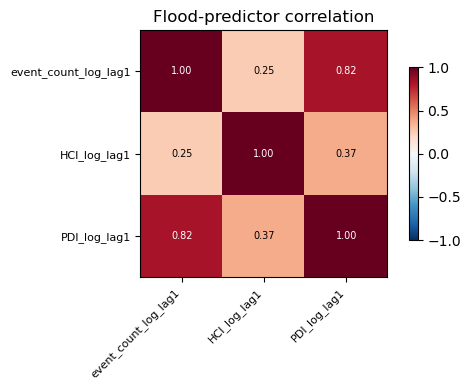

In [5]:
# correlation heatmap of flood predictors
cc = panel[FLOOD].corr()
fig, ax = plt.subplots(figsize=(1.2*len(FLOOD)+2, 1.0*len(FLOOD)+1))
im = ax.imshow(cc.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FLOOD))); ax.set_xticklabels(FLOOD, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(FLOOD))); ax.set_yticklabels(FLOOD, fontsize=8)
for i in range(len(FLOOD)):
    for j in range(len(FLOOD)):
        ax.text(j, i, f"{cc.values[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(cc.values[i,j])>0.5 else "black")
plt.colorbar(im, shrink=0.7); ax.set_title("Flood-predictor correlation"); plt.tight_layout(); plt.show()

## STEP 3 — Estimator selection — CEM vs FE vs RE (Chow · LM · Hausman)

In [7]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Estimator selection — CEM vs FE vs RE
# ═════════════════════════════════════════════════════════════
Y = "grdp_growth_pct"
sub = pdat[[Y]+X].dropna()
cem = PooledOLS(sub[Y], sub[X].assign(const=1)).fit()
fe  = PanelOLS(sub[Y], sub[X], entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
re  = RandomEffects(sub[Y], sub[X].assign(const=1)).fit()
print("ESTIMATORS")
print(f"  CEM (Pooled OLS): R2={cem.rsquared:.4f}")
print(f"  Fixed Effects   : within-R2={fe.rsquared_within:.4f}")
print(f"  Random Effects  : R2={re.rsquared:.4f}")

print(f"\n[Chow] F-test entity effects (CEM vs FE): F={fe.f_pooled.stat:.2f}, p={fe.f_pooled.pval:.4g}")
print("   -> " + ("entity effects significant -> FE over CEM" if fe.f_pooled.pval<0.05 else "CEM adequate"))

_u = pd.DataFrame({"u": cem.resids.values}, index=cem.resids.index)
_g = _u.groupby(level=0)["u"]; _T=_g.count(); _n=len(_u)
if _T.nunique()==1:
    LM=(_n/(2*(_T.iloc[0]-1)))*((_g.sum()**2).sum()/(_u["u"]**2).sum()-1)**2
    print(f"[LM]   Breusch-Pagan (CEM vs RE): LM={LM:.2f}, p={1-chi2.cdf(LM,1):.4g}")
    print("   -> " + ("individual effects present -> panel needed" if (1-chi2.cdf(LM,1))<0.05 else "no individual effects"))

common=[c for c in FLOOD if c in fe.params.index and c in re.params.index]
d=(fe.params[common]-re.params[common]).values
vd=(fe.cov.loc[common,common]-re.cov.loc[common,common]).values
h=float(d.T@np.linalg.pinv(vd)@d)
print(f"[Hausman] FE vs RE: chi2={h:.2f}, p={1-chi2.cdf(h,len(common)):.4g}")
flips=sum(1 for v in common if fe.params[v]*re.params[v]<0)
if h<0: print("   -> NEGATIVE (clustered-SE artifact); decide via coefficient gaps + theory")
print(f"   FE vs RE sign flips: {flips} -> "+("RE biased -> FE consistent" if flips else "similar"))
print("\nDECISION: Fixed Effects (Chow+LM reject pooled; FE/RE divergence + theory -> RE inconsistent).")

ESTIMATORS
  CEM (Pooled OLS): R2=0.0064
  Fixed Effects   : within-R2=0.0022
  Random Effects  : R2=0.0050

[Chow] F-test entity effects (CEM vs FE): F=20.36, p=0
   -> entity effects significant -> FE over CEM
[LM]   Breusch-Pagan (CEM vs RE): LM=135.58, p=0
   -> individual effects present -> panel needed
[Hausman] FE vs RE: chi2=-43.56, p=1
   -> NEGATIVE (clustered-SE artifact); decide via coefficient gaps + theory
   FE vs RE sign flips: 0 -> similar

DECISION: Fixed Effects (Chow+LM reject pooled; FE/RE divergence + theory -> RE inconsistent).


## STEP 4 — Significance across 17 sectors — BH-FDR vs uncorrected

17 sectors = 17 simultaneous tests per flood dimension. Without correction ~1 in 20 is a false positive. We show **both** uncorrected and BH-FDR-corrected significance so the effect of multiple-testing control is explicit. BH-FDR is applied per dimension (each dimension = its own family).

In [9]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Significance across 17 sectors — BH-FDR vs uncorrected
# ═════════════════════════════════════════════════════════════
SECTORS = ["grdp_A_agriculture","grdp_B_mining","grdp_C_manufacturing","grdp_D_electricity",
           "grdp_E_water","grdp_F_construction","grdp_G_trade","grdp_H_transport",
           "grdp_I_accommodation","grdp_J_infocomm","grdp_K_finance","grdp_L_realestate",
           "grdp_MN_business","grdp_O_government","grdp_P_education","grdp_Q_health","grdp_RSTU_other"]
for s in SECTORS:
    if f"{s}_growth" not in panel.columns:
        g = panel.groupby("bps_kab_code")[s].pct_change()*100
        g = g.replace([np.inf,-np.inf],np.nan); lo,hi=g.quantile([.01,.99]); panel[f"{s}_growth"]=g.clip(lo,hi)
pdat = panel.set_index(["bps_kab_code","year"])

rows=[]
for s in SECTORS:
    sub=pdat[[f"{s}_growth"]+X].dropna()
    r=PanelOLS(sub[f"{s}_growth"],sub[X],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    row={"sector":s.replace("grdp_","")}
    for f in FLOOD:
        row[f"b_{f}"]=r.params[f]; row[f"p_{f}"]=r.pvalues[f]
    rows.append(row)
res=pd.DataFrame(rows)
# BH per flood dimension
for f in FLOOD:
    res[f"pBH_{f}"]=multipletests(res[f"p_{f}"].values,method="fdr_bh")[1]
    res[f"sigRAW_{f}"]=res[f"p_{f}"]<0.05
    res[f"sigBH_{f}"]=res[f"pBH_{f}"]<0.05

print("Significant sectors — UNCORRECTED vs BH-FDR (per flood dimension):\n")
for f in FLOOD:
    raw=list(res.loc[res[f"sigRAW_{f}"],"sector"])
    bh =list(res.loc[res[f"sigBH_{f}"],"sector"])
    print(f"  {f}:")
    print(f"    uncorrected (p<0.05): {len(raw)} -> {raw if raw else 'none'}")
    print(f"    BH-FDR      (p<0.05): {len(bh)} -> {bh if bh else 'none'}")
    print(f"    dropped by correction: {sorted(set(raw)-set(bh)) or 'none'}\n")
print("  Interpretation: sectors that survive BH-FDR are the defensible claims;")
print("  those dropped were likely false positives from multiple testing.")

Significant sectors — UNCORRECTED vs BH-FDR (per flood dimension):

  event_count_log_lag1:
    uncorrected (p<0.05): 3 -> ['B_mining', 'E_water', 'G_trade']
    BH-FDR      (p<0.05): 3 -> ['B_mining', 'E_water', 'G_trade']
    dropped by correction: none

  HCI_log_lag1:
    uncorrected (p<0.05): 5 -> ['D_electricity', 'I_accommodation', 'MN_business', 'P_education', 'RSTU_other']
    BH-FDR      (p<0.05): 3 -> ['MN_business', 'P_education', 'RSTU_other']
    dropped by correction: ['D_electricity', 'I_accommodation']

  PDI_log_lag1:
    uncorrected (p<0.05): 3 -> ['B_mining', 'C_manufacturing', 'E_water']
    BH-FDR      (p<0.05): 1 -> ['B_mining']
    dropped by correction: ['C_manufacturing', 'E_water']

  Interpretation: sectors that survive BH-FDR are the defensible claims;
  those dropped were likely false positives from multiple testing.


#### Mundlak test (FE vs RE) — 17 sectors

Estimator selection is assessed per sector, since each sector is an independent
fixed-effects regression on the lagged (Option B) specification. For each
sector the Mundlak (1978) test checks whether the within-regency means of the
regressors are jointly significant; a significant result indicates that random
effects would be inconsistent and **fixed effects are preferred**. This
replaces the Hausman test, which was not positive-definite under clustered
errors.

**Reporting:** the result is summarised in aggregate (the number of sectors in
which FE is preferred), not as 17 separate p-values. Where the large majority
reject random effects, fixed effects are applied uniformly across all sectors
to preserve the comparability of coefficients across the sectoral models;
switching estimators for a minority of sectors would break that comparability.
As with the other outcomes, the test concerns the estimator, not the flood
hypothesis.

In [11]:
from linearmodels.panel import RandomEffects
from scipy.stats import chi2

def mundlak_test(pdat, outcome, X, label=""):
    """Mundlak CRE test (Option B: lagged flood + contemporaneous controls).
    Returns dict with Wald stat, p-value, verdict."""
    sub = pdat[[outcome] + X].dropna().copy()
    if len(sub) == 0:
        return {"label": label, "wald": np.nan, "p": np.nan, "verdict": "no data"}
    gm = sub.groupby(level=0)[X].transform("mean")
    gm.columns = [f"{c}_gm" for c in X]
    X_aug = pd.concat([sub[X], gm], axis=1).assign(const=1)
    try:
        re = RandomEffects(sub[outcome], X_aug).fit()
        gm_cols = [f"{c}_gm" for c in X]
        b = re.params[gm_cols].values
        V = re.cov.loc[gm_cols, gm_cols].values
        wald = float(b @ np.linalg.pinv(V) @ b)
        p = float(chi2.sf(wald, len(gm_cols)))
        if wald < 0:
            verdict = "NEGATIVE Wald (artefact) -> fall back to Chow+LM+theory"
        elif p < 0.05:
            verdict = "FE preferred (reject RE)"
        else:
            verdict = "RE may be adequate (re-check)"
        return {"label": label, "wald": wald, "p": p, "verdict": verdict}
    except Exception as e:
        return {"label": label, "wald": np.nan, "p": np.nan, "verdict": f"failed: {str(e)[:40]}"}

In [12]:
# ── Mundlak (FE vs RE) — per sector ──
print("\nMUNDLAK TEST (FE vs RE) per sector — replaces non-positive-definite Hausman")
print(f"  {'sector':<16}{'Wald':>10}{'p':>12}  verdict")
print("  " + "-" * 56)
mundlak_rows = []
for s in SECTORS:
    _m = mundlak_test(pdat, f"{s}_growth", X, label=s.replace("grdp_", ""))
    mundlak_rows.append(_m)
    print(f"  {_m['label']:<16}{_m['wald']:>10.3f}{_m['p']:>12.4g}  {_m['verdict']}")
mundlak_sec = pd.DataFrame(mundlak_rows)
_n_fe   = int((mundlak_sec["p"] < 0.05).sum())
_n_neg  = int((mundlak_sec["wald"] < 0).sum())
print("  " + "-" * 56)
print(f"  FE preferred (p<0.05): {_n_fe}/{len(SECTORS)} sectors"
      + (f"  |  negative-Wald artefacts: {_n_neg}" if _n_neg else ""))
# NOTE: Report the AGGREGATE, not 17 separate p-values. If the large majority
# reject RE, state FE is used uniformly across sectors for cross-sector
# comparability. Do NOT switch to RE for a few sectors - mixing estimators
# would break the comparability of coefficients across the 17 sectoral models.


MUNDLAK TEST (FE vs RE) per sector — replaces non-positive-definite Hausman
  sector                Wald           p  verdict
  --------------------------------------------------------
  A_agriculture       23.556   0.0002641  FE preferred (reject RE)
  B_mining            19.112    0.001832  FE preferred (reject RE)
  C_manufacturing     15.518    0.008363  FE preferred (reject RE)
  D_electricity       12.523     0.02828  FE preferred (reject RE)
  E_water            220.070   1.435e-45  FE preferred (reject RE)
  F_construction     160.555   7.537e-33  FE preferred (reject RE)
  G_trade             41.005   9.359e-08  FE preferred (reject RE)
  H_transport         77.765   2.462e-15  FE preferred (reject RE)
  I_accommodation     57.631   3.748e-11  FE preferred (reject RE)
  J_infocomm         416.940   6.619e-88  FE preferred (reject RE)
  K_finance           27.538   4.481e-05  FE preferred (reject RE)
  L_realestate        53.931   2.165e-10  FE preferred (reject RE)
  MN_busin

## STEP 5 — Clustered vs Driscoll–Kraay — per-sector comparison + per-sector CD test

SE choice can matter differently per sector. We report both SEs and a per-sector Pesaran CD test, so sectors with strong spatial dependence (where DK is preferred) are visible.

In [14]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Clustered vs Driscoll–Kraay — per-sector CD test
# ═════════════════════════════════════════════════════════════
def cd(resid):
    wide=resid.unstack(level=0); cmat=wide.corr().values
    n=cmat.shape[0]; T=wide.shape[0]; off=cmat[np.triu_indices(n,1)]; off=off[~np.isnan(off)]
    return np.sqrt(2*T/len(off))*off.sum()

rows=[]
for s in SECTORS:
    sub=pdat[[f"{s}_growth"]+X].dropna()
    m=PanelOLS(sub[f"{s}_growth"],sub[X],entity_effects=True,time_effects=True,drop_absorbed=True)
    rc=m.fit(cov_type="clustered",cluster_entity=True); rd=m.fit(cov_type="kernel")
    # Two adequacy tests:
    #  (a) overall model F-test (all 5 predictors = 0) — reported for context
    #  (b) flood-block Wald test (event+HCI+PDI = 0) — the CORRECT joint test for
    #      "does the flood block explain sector growth?"; used as the model gate.
    _wald = rd.wald_test(formula=" = 0, ".join(FLOOD) + " = 0")
    rows.append({"sector":s.replace("grdp_",""),"CD":cd(rd.resids),
                 "overall_F_pval":float(rd.f_statistic.pval),          # all predictors (context only)
                 "flood_block_pval":float(_wald.pval),                 # flood block joint test (the gate)
                 "model_significant":bool(_wald.pval<0.05),            # gate on flood block, NOT overall F
                 **{f"pcl_{f}":rc.pvalues[f] for f in FLOOD},
                 **{f"pdk_{f}":rd.pvalues[f] for f in FLOOD}})
se=pd.DataFrame(rows)
print("Per-sector CD test (spatial dependence on residuals):\n")
for _,r in se.sort_values("CD",ascending=False).iterrows():
    tag="STRONG -> DK preferred" if abs(r["CD"])>1.96 else "weak -> clustered ok"
    print(f"  {r['sector']:<16} CD={r['CD']:>7.2f}  {tag}")
print("\n  Sectors with strong spatial dependence need DK; others are SE-insensitive.")

Per-sector CD test (spatial dependence on residuals):

  H_transport      CD=  59.69  STRONG -> DK preferred
  K_finance        CD=  11.91  STRONG -> DK preferred
  C_manufacturing  CD=  11.69  STRONG -> DK preferred
  MN_business      CD=   7.38  STRONG -> DK preferred
  J_infocomm       CD=   7.14  STRONG -> DK preferred
  I_accommodation  CD=   6.22  STRONG -> DK preferred
  RSTU_other       CD=   3.78  STRONG -> DK preferred
  Q_health         CD=   2.47  STRONG -> DK preferred
  F_construction   CD=   1.16  weak -> clustered ok
  A_agriculture    CD=   0.53  weak -> clustered ok
  G_trade          CD=   0.11  weak -> clustered ok
  D_electricity    CD=  -0.17  weak -> clustered ok
  B_mining         CD=  -0.23  weak -> clustered ok
  L_realestate     CD=  -0.33  weak -> clustered ok
  O_government     CD=  -1.03  weak -> clustered ok
  E_water          CD=  -1.81  weak -> clustered ok
  P_education      CD=  -2.14  STRONG -> DK preferred

  Sectors with strong spatial dependence n

## STEP 6 — Model evaluation & robustness

Residual diagnostics (heteroskedasticity, normality, autocorrelation) with plots, coefficient stability across the control ladder, and robustness to SE & sample. Diagnostics use the headline outcome; for sector files the same code applies per chosen sector.

RESIDUAL DIAGNOSTICS
  Jarque-Bera (normality)        stat=35587.9  p=0  -> non-normal
  Breusch-Pagan (heterosked.)    LM=44.4  p=1.879e-08  -> heteroskedastic
  Durbin-Watson (autocorr.)      1.883  (2 = none)
  Skewness=0.568  Excess kurtosis=13.540

  -> heavy tails / heteroskedasticity expected in regency panels; handled by
     robust SEs (clustered / Driscoll-Kraay) + large-n CLT, NOT by changing the model.


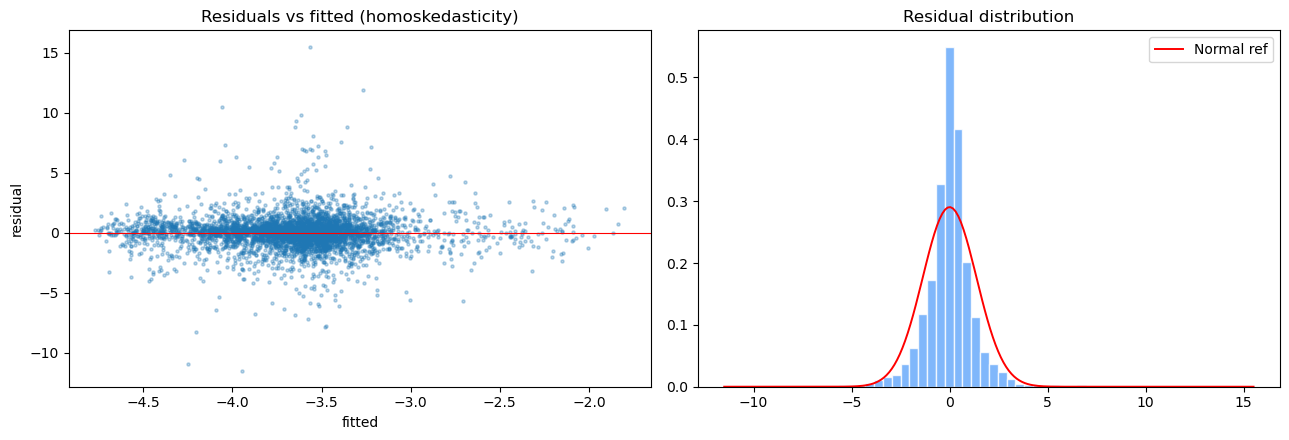

In [16]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Model evaluation & robustness
# ═════════════════════════════════════════════════════════════
Y_EVAL = "grdp_growth_pct"
sub = pdat[[Y_EVAL]+X].dropna()
fe = PanelOLS(sub[Y_EVAL], sub[X], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
resid = fe.resids.values.ravel(); fitted = fe.fitted_values.values.ravel()

# diagnostic statistics
jb_stat, jb_p = jarque_bera(resid)
from scipy import stats as _st
skew=_st.skew(resid); exkurt=_st.kurtosis(resid)
_ex = sub[X].loc[fe.resids.index]
bp_lm, bp_p, _, _ = het_breuschpagan(resid, np.column_stack([np.ones(len(_ex)), _ex.values]))
dw = durbin_watson(resid)
print("RESIDUAL DIAGNOSTICS")
print(f"  Jarque-Bera (normality)        stat={jb_stat:.1f}  p={jb_p:.4g}  -> {'non-normal' if jb_p<0.05 else 'normal'}")
print(f"  Breusch-Pagan (heterosked.)    LM={bp_lm:.1f}  p={bp_p:.4g}  -> {'heteroskedastic' if bp_p<0.05 else 'homoskedastic'}")
print(f"  Durbin-Watson (autocorr.)      {dw:.3f}  (2 = none)")
print(f"  Skewness={skew:.3f}  Excess kurtosis={exkurt:.3f}")
print("\n  -> heavy tails / heteroskedasticity expected in regency panels; handled by")
print("     robust SEs (clustered / Driscoll-Kraay) + large-n CLT, NOT by changing the model.")

fig, ax = plt.subplots(1, 2, figsize=(13,4.5))
ax[0].scatter(fitted, resid, s=5, alpha=0.3); ax[0].axhline(0, color="red", lw=.8)
ax[0].set_title("Residuals vs fitted (homoskedasticity)"); ax[0].set_xlabel("fitted"); ax[0].set_ylabel("residual")
ax[1].hist(resid, bins=60, density=True, color="#60a5fa", edgecolor="white", alpha=.8)
_xx=np.linspace(resid.min(),resid.max(),200); ax[1].plot(_xx,_st.norm.pdf(_xx,resid.mean(),resid.std()),"r-",lw=1.4,label="Normal ref")
ax[1].set_title("Residual distribution"); ax[1].legend(); plt.tight_layout(); plt.show()

In [17]:
# Coefficient stability across control ladder (key flood predictor)
KEY = FLOOD[-1] if "sector"=="growth" else FLOOD[-1]
KEY = "fasum_damaged_log" if "fasum_damaged_log" in FLOOD else FLOOD[-1]
Y_EVAL = "grdp_growth_pct"
ladder = [("flood only", FLOOD), ("+ log_population", FLOOD+["log_population"]),
          ("+ rls_years (FULL)", FLOOD+CONTROLS)]
print(f"Coefficient stability of {KEY} on {Y_EVAL} (Driscoll-Kraay):\n")
print(f"  specification               beta        p")
bs=[]
for nm,xv in ladder:
    sub=pdat[[Y_EVAL]+xv].dropna()
    r=PanelOLS(sub[Y_EVAL],sub[xv],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    bs.append(r.params[KEY]); print(f"  {nm:<22}{r.params[KEY]:>10.4f}{r.pvalues[KEY]:>9.4f}")
print(f"  range={max(bs)-min(bs):.4f} -> {'STABLE (control-insensitive)' if max(bs)-min(bs)<abs(np.mean(bs))*0.3 else 'sensitive'}")

# robustness to SE & sample
print(f"\nRobustness of {KEY} to SE & sample:")
print(f"  variant                         beta        p")
sub=pdat[[Y_EVAL]+X].dropna()
mm=PanelOLS(sub[Y_EVAL],sub[X],entity_effects=True,time_effects=True,drop_absorbed=True)
for lab,cov in [("clustered",dict(cov_type="clustered",cluster_entity=True)),("Driscoll-Kraay",dict(cov_type="kernel")),("robust",dict(cov_type="robust"))]:
    r=mm.fit(**cov); print(f"  {lab:<26}{r.params[KEY]:>10.4f}{r.pvalues[KEY]:>9.4f}")
for lo,hi in [(2016,2020),(2021,2025)]:
    s2=panel[(panel.year>=lo)&(panel.year<=hi)].set_index(["bps_kab_code","year"])
    s2=s2[[Y_EVAL]+X].dropna()
    r=PanelOLS(s2[Y_EVAL],s2[X],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    print(f"  {f'subsample {lo}-{hi}':<26}{r.params[KEY]:>10.4f}{r.pvalues[KEY]:>9.4f}")

Coefficient stability of PDI_log_lag1 on grdp_growth_pct (Driscoll-Kraay):

  specification               beta        p
  flood only                0.0007   0.8898
  + log_population          0.0006   0.8955
  + rls_years (FULL)        0.0006   0.8975
  range=0.0000 -> STABLE (control-insensitive)

Robustness of PDI_log_lag1 to SE & sample:
  variant                         beta        p
  clustered                     0.0006   0.9499
  Driscoll-Kraay                0.0006   0.8975
  robust                        0.0006   0.9438
  subsample 2016-2020           0.0145   0.0016
  subsample 2021-2025           0.0026   0.8471


## STEP 7 — Model fit summary (AIC / BIC / R² / F / RMSE)

Reference metrics for this specification. **Important:** AIC and BIC are *relative* measures — a single value is not interpretable on its own; it is only meaningful when **compared across files** on the same outcome (e.g. this file's AIC vs the 7-variable file's AIC for growth, or 3-dim vs 7-var for sectors). Record these values and compare them in `9b_model_comparison_3dim_vs_7comp.ipynb`.

- **within-R² / adj. within-R²** — variation explained within regencies (adjusted penalises extra parameters)
- **AIC / BIC** — fit penalised for complexity; lower = better; BIC penalises parameters more strongly
- **log-likelihood** — model fit (higher = better)
- **F-statistic** — joint significance of all regressors
- **RMSE** — residual standard deviation (typical prediction error)

In [19]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — Model fit summary per sector
# ═════════════════════════════════════════════════════════════
def model_fit_summary(res, n_params):
    n = res.nobs
    return {
        "within_R2":     res.rsquared_within,
        "adj_within_R2": 1 - (1 - res.rsquared_within) * (n - 1) / (n - n_params - 1),
        "AIC":           2 * n_params - 2 * res.loglik,
        "BIC":           n_params * np.log(n) - 2 * res.loglik,
        "logLik":        res.loglik,
        "RMSE":          res.resids.std(),
        "n":             int(n),
    }

# per-sector fit metrics, then aggregate (17 sectors -> summary stats)
fit_rows = []
for s in SECTORS:
    sub = pdat[[f"{s}_growth"] + X].dropna()
    r = PanelOLS(sub[f"{s}_growth"], sub[X], entity_effects=True, time_effects=True,
                 drop_absorbed=True).fit(cov_type="kernel")
    m = model_fit_summary(r, len(X)); m["sector"] = s.replace("grdp_", "")
    fit_rows.append(m)
fitdf = pd.DataFrame(fit_rows).set_index("sector")

print(f"MODEL FIT PER SECTOR ({len(FLOOD)}-variable flood spec) — AIC/BIC/within-R2:\n")
print(fitdf[["within_R2", "adj_within_R2", "AIC", "BIC", "RMSE"]].round(3).to_string())
print(f"""
  AGGREGATE across 17 sectors:
    within-R2 : mean={fitdf['within_R2'].mean():.4f}  range=[{fitdf['within_R2'].min():.4f}, {fitdf['within_R2'].max():.4f}]
    AIC       : mean={fitdf['AIC'].mean():.0f}  range=[{fitdf['AIC'].min():.0f}, {fitdf['AIC'].max():.0f}]
    BIC       : mean={fitdf['BIC'].mean():.0f}  range=[{fitdf['BIC'].min():.0f}, {fitdf['BIC'].max():.0f}]

  To compare 3-dim vs 7-var at sector level: compare the SAME sector's AIC/BIC
  across the two files (lower = better). Aggregate mean AIC/BIC gives the overall
  picture; BIC is the parsimony-strict criterion. Single values are reference only.""")

MODEL FIT PER SECTOR (3-variable flood spec) — AIC/BIC/within-R2:

                 within_R2  adj_within_R2        AIC        BIC   RMSE
sector                                                                
A_agriculture       -0.003         -0.004  19504.593  19536.791  1.990
B_mining            -0.003         -0.004  26231.263  26263.205  4.776
C_manufacturing      0.002          0.001  24591.953  24624.146  3.457
D_electricity       -0.008         -0.009  25692.881  25725.018  4.017
E_water              0.007          0.006  22078.719  22110.770  2.822
F_construction       0.024          0.023  24336.365  24368.562  3.355
G_trade              0.005          0.004  20218.089  20250.286  2.150
H_transport         -0.009         -0.010  29244.097  29276.294  5.703
I_accommodation     -0.013         -0.014  25461.150  25493.347  3.789
J_infocomm           0.040          0.039  21474.899  21507.087  2.474
K_finance            0.001         -0.000  24343.404  24375.552  3.446
L_realesta

## STEP 8 — Save sector results → fit_9b.json (for the dashboard bar chart)

Exports per-sector × per-dimension coefficients with both SE families, so the
dashboard reads the EXACT 9b results (single source of truth — no recompute).

For each sector × {event, HCI, PDI}:
- `beta`, `pBH_clustered`, `pBH_DK` (both BH-FDR corrected)
- `flag`: `**` robust (sig both SE) · `~cl` clustered-only · `~dk` DK-only · `` n.s.
- `CD`: per-sector Pesaran cross-sectional dependence (context)

In [38]:
# ═════════════════════════════════════════════════════════════
# STEP 8 — Save per-sector results
# ═════════════════════════════════════════════════════════════
# ── SAVE sector results to fit_9b.json (dashboard bar chart source) ──
import json
from statsmodels.stats.multitest import multipletests

# `res` (cell with clustered + BH) and `se` (cell with CD + pcl/pdk) exist above.
# Apply BH-FDR to the DK p-values too (per dimension), to mirror the clustered BH.
_se = se.copy()
for f in FLOOD:
    _se[f"pdkBH_{f}"] = multipletests(_se[f"pdk_{f}"].values, method="fdr_bh")[1]
    _se[f"pclBH_{f}"] = multipletests(_se[f"pcl_{f}"].values, method="fdr_bh")[1]

# beta per sector×dim — recover from `res` if present, else from a fresh fit
def _beta_lookup(sector, f):
    r = res[res["sector"] == sector]
    col = f"b_{f}" if f"b_{f}" in res.columns else None
    if col is not None and len(r):
        return float(r[col].iloc[0])
    return None

_dim_name = {FLOOD[0]: "event", FLOOD[1]: "HCI", FLOOD[2]: "PDI"}
sectors_out = {}
for _, r in _se.iterrows():
    sec = r["sector"]
    dims = {}
    for f in FLOOD:
        pcl = float(r[f"pclBH_{f}"]); pdk = float(r[f"pdkBH_{f}"])
        sig_cl, sig_dk = pcl < 0.05, pdk < 0.05
        flag = ("**" if sig_cl and sig_dk else
                "~cl" if sig_cl else
                "~dk" if sig_dk else "")
        dims[_dim_name[f]] = {
            "beta": _beta_lookup(sec, f),
            "pBH_clustered": pcl, "pBH_DK": pdk, "flag": flag,
            "sig_any": bool(sig_cl or sig_dk),
        }
    sectors_out[sec] = {"CD": float(r["CD"]),
                        "overall_F_pval": float(r["overall_F_pval"]),
                        "flood_block_pval": float(r["flood_block_pval"]),
                        "model_significant": bool(r["model_significant"]),
                        "dims": dims}

payload = {
    "file": "9b", "spec": "3-dimension (event, HCI, PDI)", "outcome": "sector growth",
    "n_sectors": len(sectors_out),
    "flag_legend": {"**": "robust (sig both SE)", "~cl": "clustered-only",
                    "~dk": "DK-only", "": "n.s."},
    "model_note": "model_significant = flood block jointly significant via Wald test (event+HCI+PDI=0, p<0.05); overall_F_pval (all predictors) reported for context only",
    "sectors": sectors_out,
}
with open("../data/processed/fit_9b.json", "w") as _f:
    json.dump(payload, _f, indent=2)

# summary
_robust = [(s, d) for s, v in sectors_out.items() for d, x in v["dims"].items() if x["flag"] == "**"]
_sugg   = [(s, d) for s, v in sectors_out.items() for d, x in v["dims"].items() if x["flag"].startswith("~")]
print(f"✓ saved fit_9b.json — {len(sectors_out)} sectors")
print(f"  ROBUST (**):     {len(_robust)} -> {_robust}")
print(f"  SUGGESTIVE (~):  {len(_sugg)}")
print(f"  (the rest are n.s. — reported in the dashboard note)")

✓ saved fit_9b.json — 17 sectors
  ROBUST (**):     3 -> [('B_mining', 'event'), ('E_water', 'event'), ('G_trade', 'event')]
  SUGGESTIVE (~):  4
  (the rest are n.s. — reported in the dashboard note)


## STEP 9 — Master sector table & grouped summary (for the thesis write-up)

In [23]:
# ═════════════════════════════════════════════════════════════
# STEP 9 — Master sector table & grouped summary
# ═════════════════════════════════════════════════════════════
# ── Master sector table + grouped summary (printed for the thesis) ──
# Uses `sectors_out` + `_se` built in the save cell above.
print("MASTER SECTOR TABLE — beta | pBH(clustered) | pBH(Driscoll-Kraay) | flag")
print("  flags: ** = sig BOTH SEs (robust)   ~cl = clustered only   ~dk = DK only\n")
_hdr = f"{'sector':<15}|  {'event (b / pCL / pDK / f)':<26} |  {'HCI (b / pCL / pDK / f)':<26} |  {'PDI (b / pCL / pDK / f)':<26}"
print(_hdr); print("-" * len(_hdr))
for sec, v in sectors_out.items():
    cells = []
    for dim in ["event", "HCI", "PDI"]:
        d = v["dims"][dim]
        b = d["beta"]; pcl = d["pBH_clustered"]; pdk = d["pBH_DK"]; fl = d["flag"]
        cells.append(f"{b:+.3f}  {pcl:.3f}  {pdk:.3f}  {fl:<4}")
    print(f"{sec:<15}| {cells[0]:<27}| {cells[1]:<27}| {cells[2]:<27}")

# grouped summary by SE agreement
print("\n" + "=" * 74)
print("SUMMARY — significant sector x dimension effects, grouped by SE agreement")
print("(BH-FDR corrected; model_significant = flood block jointly sig via F-test)\n")

def _collect(flag_test):
    out = []
    for sec, v in sectors_out.items():
        for dim, d in v["dims"].items():
            if flag_test(d["flag"]):
                out.append((sec, dim, d["beta"], d["pBH_clustered"], d["pBH_DK"],
                            v.get("model_significant", True)))
    return out

_groups = [
    ("1. ROBUST  — significant under BOTH clustered AND Driscoll-Kraay:",
     lambda f: f == "**"),
    ("2. CLUSTERED SE ONLY  — significant under clustered, NOT under DK:",
     lambda f: f == "~cl"),
    ("3. DRISCOLL-KRAAY SE ONLY  — significant under DK, NOT under clustered:",
     lambda f: f == "~dk"),
]
for title, test in _groups:
    print(title)
    for sec, dim, b, pcl, pdk, mok in _collect(test):
        gate = "" if mok else "   [flood-block Wald n.s. -> would be excluded]"
        print(f"    {sec:<16} [{dim:<5}] beta={b:+.4f}  pBH_cl={pcl:.4f}  pBH_dk={pdk:.4f}{gate}")
    print()


# ── Model-adequacy table: two joint F-tests per sector ──────────────
print("\n" + "=" * 74)
print("MODEL ADEQUACY — joint tests per sector")
print("  overall-F   : H0 all predictors (flood + controls) = 0  (context only)")
print("  flood-Wald  : H0 flood block (event=HCI=PDI) = 0  (THE gate, p<0.05)")
print("  gate        : ✓ = flood block jointly significant -> effects shown\n")
print(f"  {'sector':<16}{'overall-F p':>13}{'flood-Wald p':>14}{'  gate':<8}")
print("  " + "-" * 52)
for sec, v in sectors_out.items():
    ofp = v.get("overall_F_pval", float("nan"))
    fwp = v.get("flood_block_pval", float("nan"))
    gate = "✓ sig" if v.get("model_significant") else "✗ n.s."
    print(f"  {sec:<16}{ofp:>13.4f}{fwp:>14.4f}  {gate:<8}")
print("  " + "-" * 52)
_n_gate = sum(v.get("model_significant", False) for v in sectors_out.values())
print(f"  flood block jointly significant: {_n_gate}/{len(sectors_out)} sectors")
print("""
  NOTE: overall-F and flood-Wald can DISAGREE. e.g. RSTU_other & B_mining have
  overall-F n.s. (controls add little) but flood-Wald SIGNIFICANT. Gating on the
  flood-block Wald (not overall-F) is correct: it isolates the flood contribution,
  which is exactly what the reported effects claim. No significant effect is
  dropped — all come from sectors whose flood block is jointly significant.""")


MASTER SECTOR TABLE — beta | pBH(clustered) | pBH(Driscoll-Kraay) | flag
  flags: ** = sig BOTH SEs (robust)   ~cl = clustered only   ~dk = DK only

sector         |  event (b / pCL / pDK / f)  |  HCI (b / pCL / pDK / f)    |  PDI (b / pCL / pDK / f)   
--------------------------------------------------------------------------------------------------------
A_agriculture  | +0.019  0.872  0.908       | +0.005  0.954  0.928       | -0.010  0.677  0.727       
B_mining       | +0.745  0.011  0.002  **   | -0.080  0.954  0.928       | -0.070  0.352  0.000  ~dk  
C_manufacturing| -0.106  0.844  0.740       | -0.043  0.954  0.928       | +0.041  0.352  0.257       
D_electricity  | -0.101  0.844  0.740       | -0.088  0.755  0.112       | +0.038  0.503  0.335       
E_water        | +0.386  0.013  0.006  **   | +0.011  0.954  0.928       | -0.040  0.352  0.164       
F_construction | -0.136  0.844  0.740       | -0.023  0.954  0.928       | +0.023  0.625  0.496       
G_trade        | +0.302

## STEP 10 — Sector effects shown in the dashboard (lagged specification)

This is the **lagged** (Option B, t−1) robustness run; the contemporaneous
3-dimension file (`9b_sectors_3dim`) remains the headline reported in the
manuscript. The results here are shown only to test whether the sector effects
are immediate or delayed.

Under the lagged specification the BH-FDR–corrected results identify **7
significant sector × dimension effects** out of the 51 tested (17 sectors × 3
flood dimensions): **3 robust** (significant under both clustered and
Driscoll–Kraay SE — B_mining, E_water, and G_trade, all on event frequency) and
**4 suggestive** (significant under one SE type only). The flood block is jointly
significant (Wald p < 0.05) in **10 of 17** sectors.

**Model-adequacy check (two joint tests).** For each sector two tests are
reported: the overall model F-test (all predictors = 0, context only, because it
mixes the flood block with the controls) and the flood-block Wald test (the three
flood coefficients jointly = 0), which is the correct test for "does the flood
block explain sector growth?" and is used as the model-adequacy gate. All
reported effects come from sectors whose flood block is jointly significant.

**Interpretation.** The set of robust sectors differs from the contemporaneous
run and the individual significances are generally weaker, consistent with the
manuscript's finding that the flood–growth association is contemporaneous rather
than persistent: a one-year lag does not strengthen it. The full 17 × 3 master
table and both joint tests per sector are reported above for transparency.